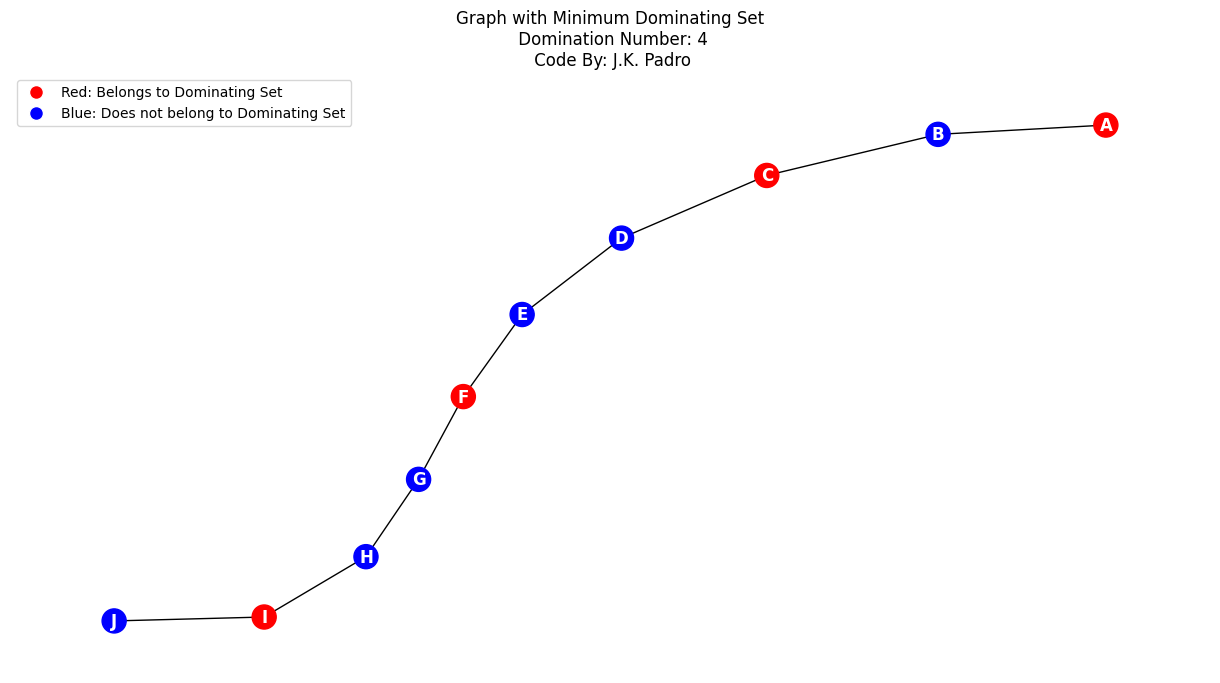

In [4]:
import networkx as nx
import itertools

def is_valid_dominating_set(G, node_set):
    """
    Check if a given node set is a valid dominating set for the graph G.
    
    Parameters:
    G (networkx.Graph): The input graph
    node_set (set): The set of nodes to check
    
    Returns:
    bool: True if the node_set is a valid dominating set, False otherwise
    """
    for node in G.nodes():
        # Node must either be in the set or have an adjacent node in the set
        if node not in node_set and not any(neigh in node_set for neigh in G.neighbors(node)):
            return False
    return True

def minimum_dominating_set(G):
    """
    Find the minimum dominating set for the given graph by checking all subsets.
    
    Parameters:
    G (networkx.Graph): The input graph
    
    Returns:
    set: The minimum dominating set
    """
    # Initialize the minimum dominating set as None
    min_dominating_set = None
    
    # Get all possible subsets of nodes
    all_nodes = list(G.nodes())
    for r in range(1, len(all_nodes) + 1):
        for subset in itertools.combinations(all_nodes, r):
            node_set = set(subset)
            if is_valid_dominating_set(G, node_set):
                # If the current set is valid and smaller than the current minimum, update
                if min_dominating_set is None or len(node_set) < len(min_dominating_set):
                    min_dominating_set = node_set
    
    return min_dominating_set

# Example usage
def test_minimum_dominating_set():
    # Create a sample graph
    G = nx.Graph()
    G.add_edges_from([
        ('A','B'), ('B','C'), ('C','D'), ('D','E'), ('E','F'), ('F','G'), ('G','H'), ('H','I'), ('I','J')
    ])
    
    # Find the minimum dominating set
    min_set = minimum_dominating_set(G)
    
    #print(f"Minimum Dominating Set: {min_set}")
    
    # Verify that it's a valid dominating set
    is_valid = True
    for node in G.nodes():
        if node not in min_set and not any(neigh in min_set for neigh in G.neighbors(node)):
            is_valid = False
            break
    
    #print(f"Is valid dominating set: {is_valid}")
    
    # Optionally visualize the graph with the minimum dominating set
    try:
        import matplotlib.pyplot as plt
        pos = nx.spring_layout(G)
        # Visualize with red nodes as part of the dominating set
        plt.figure(figsize=(12, 6))
        nx.draw(G, pos, with_labels=True, node_color=['r' if node in min_set else 'b' for node in G.nodes()], font_weight='bold', font_size=12, font_color='white')
        plt.title(f"Graph with Minimum Dominating Set\n Domination Number: {len(min_set)}\n Code By: J.K. Padro")
        
        # Add a legend to the plot
        red_patch = plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='r', markersize=10, label='Red: Belongs to Dominating Set')
        blue_patch = plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='b', markersize=10, label='Blue: Does not belong to Dominating Set')
        plt.legend(handles=[red_patch, blue_patch], loc='best')
        
        plt.savefig("graph.jpg")
        #print("graph.png'")
        plt.show()
    except ImportError:
        print("Matplotlib not available for visualization")

# Run the test
test_minimum_dominating_set()